# 03 — Modelling

Five model families, each tuned by cross-validation on the training set. The test set is opened once, in the final section.

## 1. Setup

### 1a. Loading the split and the preprocessors

`02_preprocessing.ipynb` saved the cleaned 80/20 split and the two preprocessor definitions. The definitions are unfitted: each one is refit on the training part of every cross-validation fold, inside the pipeline it belongs to.

In [2]:
import joblib
import numpy as np
import pandas as pd

RANDOM_STATE = 42
PROCESSED_DIR = "../data/processed"
MODELS_DIR = "../models"
REPORTS_DIR = "../reports"

train = joblib.load(f"{PROCESSED_DIR}/train.joblib")
test = joblib.load(f"{PROCESSED_DIR}/test.joblib")

X_train, y_train = train.drop(columns="TARGET"), train["TARGET"]
X_test, y_test = test.drop(columns="TARGET"), test["TARGET"]

preprocessor_linear = joblib.load(f"{MODELS_DIR}/preprocessor_linear.joblib")
preprocessor_tree = joblib.load(f"{MODELS_DIR}/preprocessor_tree.joblib")

for name, X_part, y_part in [("train", X_train, y_train), ("test", X_test, y_test)]:
    print(f"{name:<6}{len(X_part):>8,} rows   {X_part.shape[1]:>3} features   "
          f"default rate {y_part.mean():.4f}")

train  246,003 rows    60 features   default rate 0.0807
test    61,501 rows    60 features   default rate 0.0807


### 1b. Cross-validation

One `StratifiedKFold` object, reused by every search below, so each family is scored on identical folds and the means are directly comparable. Both metrics are computed per fold; PR-AUC decides which configuration wins.

In [3]:
from sklearn.model_selection import StratifiedKFold

N_SPLITS = 5
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

SCORING = {"ap": "average_precision", "roc": "roc_auc"}
REFIT = "ap"

held_out = len(next(iter(cv.split(X_train, y_train)))[1])
print(f"{N_SPLITS}-fold stratified cross-validation on the training set")
print(f"  fit on   {len(X_train) - held_out:,} rows per fold")
print(f"  score on {held_out:,} rows per fold")
print(f"\nno-skill floors   PR-AUC {y_train.mean():.4f} (the positive rate)   ROC-AUC 0.5000")

5-fold stratified cross-validation on the training set
  fit on   196,802 rows per fold
  score on 49,201 rows per fold

no-skill floors   PR-AUC 0.0807 (the positive rate)   ROC-AUC 0.5000


### 1c. Pipeline shapes

Three wrappers, one per representation. Each joins a preprocessor to a model in a single estimator, which is what lets the search refit the preprocessor on every fold.

XGBoost and LightGBM read a pandas `category` dtype rather than integer codes, so a cast step sits between the two.

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

SCALE_POS_WEIGHT = (y_train == 0).sum() / (y_train == 1).sum()


def as_categorical(X):
    """Integer codes -> pandas category dtype. For XGBoost and LightGBM only."""
    X = X.copy()
    for col in X.columns:
        if col.startswith(("categorical__", "ordinal__")):
            X[col] = X[col].astype("int8").astype("category")
    return X


def linear_pipe(model):
    """Logistic Regression: median impute, scale, one-hot."""
    return Pipeline([("prep", preprocessor_linear), ("model", model)])


def tree_pipe(model):
    """Decision Tree, Random Forest: integer codes, NaN kept."""
    return Pipeline([("prep", preprocessor_tree), ("model", model)])


def boost_pipe(model):
    """XGBoost, LightGBM: integer codes recast as pandas category."""
    return Pipeline([
        ("prep", preprocessor_tree),
        ("cast", FunctionTransformer(as_categorical)),
        ("model", model),
    ])


print(f"scale_pos_weight = {SCALE_POS_WEIGHT:.3f}")

scale_pos_weight = 11.387


### 1d. The search helper

`scoring`, `refit`, `cv` and `return_train_score` are set in one place, so no family is evaluated on different terms from another. `n_iter=None` runs an exhaustive grid, any other value samples that many configurations.

Each call records one row: the winning configuration's cross-validated mean and standard deviation, its training score, and what the search cost. A winner sitting on the edge of its grid is flagged, since the range may need widening — though some boundaries are natural, such as pure L1 at `l1_ratio=1`.

`save_model` writes the refit winner to `models/` (each saved object is the whole pipeline).

In [5]:
import os
import time
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

results = []


def run_search(name, pipe, space, n_iter=None, n_jobs=-1):
    """Tune one family on the training set. n_iter=None -> exhaustive grid."""
    shared = dict(scoring=SCORING, refit=REFIT, cv=cv, return_train_score=True, n_jobs=n_jobs)
    if n_iter is None:
        search = GridSearchCV(pipe, space, **shared)
    else:
        search = RandomizedSearchCV(pipe, space, n_iter=n_iter,
                                    random_state=RANDOM_STATE, **shared)

    start = time.perf_counter()
    search.fit(X_train, y_train)
    wall = time.perf_counter() - start

    cv_res, best = search.cv_results_, search.best_index_
    row = {
        "model": name,
        "cv_ap": cv_res["mean_test_ap"][best],
        "cv_ap_std": cv_res["std_test_ap"][best],
        "cv_roc": cv_res["mean_test_roc"][best],
        "cv_gini": 2 * cv_res["mean_test_roc"][best] - 1,
        "train_ap": cv_res["mean_train_ap"][best],
        "candidates": len(cv_res["params"]),
        "wall_min": wall / 60,
        "best_params": search.best_params_,
    }
    results[:] = [r for r in results if r["model"] != name] + [row] 

    print(f"\n{'='*58}")
    print(f"{name}")
    print(f"{'='*58}")
    print(f"  CV PR-AUC    {row['cv_ap']:.4f} ± {row['cv_ap_std']:.4f}")
    print(f"  CV ROC-AUC   {row['cv_roc']:.4f}")
    print(f"  CV Gini      {row['cv_gini']:.4f}")
    print(f"  train PR-AUC {row['train_ap']:.4f}   gap {row['train_ap'] - row['cv_ap']:+.4f}")
    print(f"  {row['candidates']} candidates x {N_SPLITS} folds in {row['wall_min']:.1f} min")
    for key, value in search.best_params_.items():
        shown = f"{value:g}" if isinstance(value, (float, np.floating)) else value
        print(f"    {key.replace('model__', '')} = {shown}")

    # a winner on the edge of a numeric range is a sign the range may be too narrow
    for key, values in space.items():
        numeric = [v for v in values if isinstance(v, (int, float, np.number))]
        if len(values) > 1 and len(numeric) == len(values):
            edge = search.best_params_[key]
            if edge in (min(values), max(values)):
                print(f"    [edge] {key.replace('model__', '')} = {edge:g} "
                      f"sits on a grid boundary")
    return search


def save_model(search, filename):
    """Persist the refit winner: a full pipeline, cleaned applicant in, score out."""
    path = f"{MODELS_DIR}/{filename}"
    joblib.dump(search.best_estimator_, path)
    size_kb = os.path.getsize(path) / 1e3
    size, unit = (size_kb / 1e3, "MB") if size_kb >= 1e3 else (size_kb, "KB")
    print(f"saved {path}   {size:.1f} {unit}")

## 2. Logistic Regression

One grid over the strength of the penalty (`C`) and its composition (`l1_ratio`) — 0 is pure L2, 1 is pure L1, 0.5 an even elastic-net mix. The `saga` solver handles all three and is stable for large dataset. `tol=1e-2`, which saga reaches in about 18 iterations.

In [5]:
from sklearn.linear_model import LogisticRegression

logreg_search = run_search(
    "Logistic Regression",
    linear_pipe(LogisticRegression(
        solver="saga",
        max_iter=300,
        tol=1e-2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
    {
        "model__C": [0.01, 0.1, 1.0],
        "model__l1_ratio": [0.0, 0.5, 1.0],
    },
)

save_model(logreg_search, "logreg.joblib")


Logistic Regression
  CV PR-AUC    0.2204 ± 0.0036
  CV ROC-AUC   0.7449
  CV Gini      0.4897
  train PR-AUC 0.2211   gap +0.0008
  9 candidates x 5 folds in 2.4 min
    C = 1
    l1_ratio = 1
    [edge] C = 1 sits on a grid boundary
    [edge] l1_ratio = 1 sits on a grid boundary
saved ../models/logreg.joblib   23.7 KB


### 2a. Coefficients of the winning configuration

The numeric branch is standardised, so each coefficient is the change in log-odds of default per one standard deviation of that feature, and `exp(coefficient)` is the multiplicative change in the odds.

In [6]:
best_logreg = logreg_search.best_estimator_
feature_names = best_logreg.named_steps["prep"].get_feature_names_out()
coefficients = pd.Series(best_logreg.named_steps["model"].coef_[0], index=feature_names)

print(f"{len(coefficients)} features in   "
      f"{int((coefficients == 0).sum())} zeroed by the penalty\n")

top = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(15)
print(pd.DataFrame({"coefficient": top, "odds_ratio": np.exp(top)}).to_string(
    formatters={"coefficient": "{:+.3f}".format, "odds_ratio": "{:.3f}".format}))

96 features in   0 zeroed by the penalty

                                                 coefficient odds_ratio
numeric__EXT_SOURCE_3                                 -0.489      0.613
numeric__EXT_SOURCE_2                                 -0.392      0.676
categorical__CODE_GENDER_M                            +0.322      1.381
categorical__FLAG_OWN_CAR_Y                           -0.242      0.785
categorical__NAME_CONTRACT_TYPE_Revolving loans       -0.236      0.789
numeric__EXT_SOURCE_1                                 -0.201      0.818
flags__IS_MISSING_AMT_REQ_CREDIT_BUREAU               +0.190      1.209
flags__IS_MISSING_EXT_SOURCE_1                        +0.189      1.208
categorical__NAME_FAMILY_STATUS_Married               -0.174      0.840
numeric__EMPLOYMENT_YEARS                             -0.148      0.863
ordinal__NAME_EDUCATION_TYPE                          -0.146      0.864
flags__FLAG_DOCUMENT_3                                +0.132      1.141
categorical__EMERGENCY

## 3. Decision Tree

`min_samples_leaf` is a fraction of the fold, so it rescales with the data; the three values put roughly 16, 79 and 159 defaulters in a leaf, which is the range over which a leaf's default rate goes from noise to a usable estimate. `max_depth` steps 4 to 12 because capacity doubles with every level, with `None` included so the grid can reject a depth cap outright.

In [7]:
from sklearn.tree import DecisionTreeClassifier

TREE_SPACE = {
    "model__max_depth": [4, 6, 8, 12, None],
    "model__min_samples_leaf": [0.001, 0.005, 0.01],
}

tree_search = run_search(
    "Decision Tree",
    tree_pipe(DecisionTreeClassifier(
        class_weight="balanced", 
        random_state=RANDOM_STATE)),
    TREE_SPACE,
)

save_model(tree_search, "tree.joblib")


Decision Tree
  CV PR-AUC    0.1949 ± 0.0016
  CV ROC-AUC   0.7197
  CV Gini      0.4395
  train PR-AUC 0.2073   gap +0.0124
  15 candidates x 5 folds in 2.3 min
    max_depth = None
    min_samples_leaf = 0.005
saved ../models/tree.joblib   39.9 KB


## 4. Random Forest

`n_estimators` is fixed at 100 to keep the search cost manageable. `RandomizedSearchCV` samples 10 of the 54 possible combinations across `max_features`, `max_samples`, `max_depth`, and `min_samples_leaf`, balancing computational cost, tree diversity, and model complexity.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

RF_SPACE = {
    "model__max_features": ["sqrt", 0.3],
    "model__max_samples": [0.2, 0.3, 0.5],
    "model__max_depth": [10, 20, None],
    "model__min_samples_leaf": [0.0005, 0.001, 0.005],
}

rf_search = run_search(
    "Random Forest",
    tree_pipe(RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        n_jobs=1,  # run_search already runs one fit per core; nesting the two oversubscribes
        random_state=RANDOM_STATE,
    )),
    RF_SPACE,
    n_iter=10,
)

save_model(rf_search, "random_forest.joblib")


Random Forest
  CV PR-AUC    0.2218 ± 0.0039
  CV ROC-AUC   0.7427
  CV Gini      0.4855
  train PR-AUC 0.2578   gap +0.0360
  10 candidates x 5 folds in 7.4 min
    min_samples_leaf = 0.0005
    max_samples = 0.3
    max_features = 0.3
    max_depth = None
    [edge] min_samples_leaf = 0.0005 sits on a grid boundary
saved ../models/random_forest.joblib   6.2 MB


### 4a. Feature importance

These scores lean towards continuous and high-cardinality columns, which offer more candidate split points and so win more splits than a binary flag of equal value. They show what the forest used, not what matters — permutation importance answers that, but it needs held-out data, so it waits for the test-set section.

60 features in   3 never chosen for a split   top 10 hold 77.5% of the total


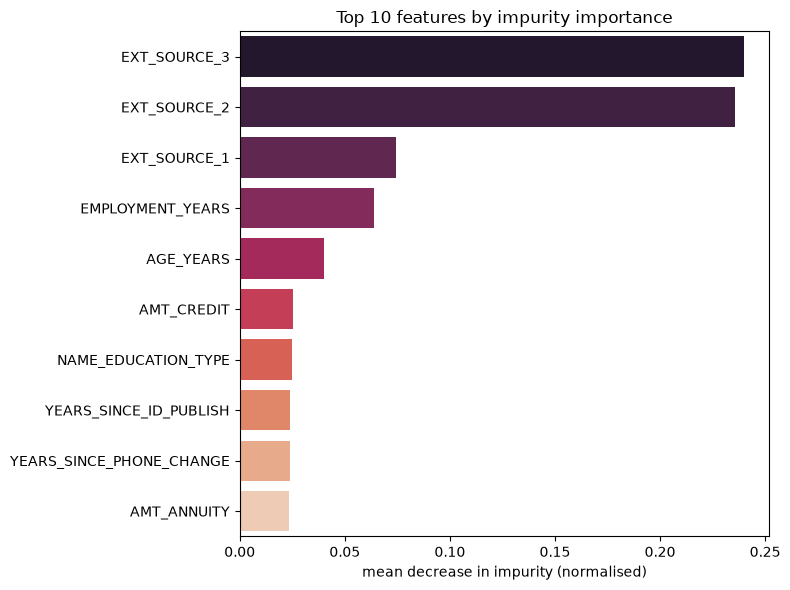

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

#best_rf = rf_search.best_estimator_
rf_features = best_rf.named_steps["prep"].get_feature_names_out()
importances = pd.Series(best_rf.named_steps["model"].feature_importances_, index=[n.split("__", 1)[1] for n in rf_features])

print(f"{len(importances)} features in   "
      f"{int((importances == 0).sum())} never chosen for a split   "
      f"top 10 hold {importances.nlargest(10).sum():.1%} of the total")

top = importances.nlargest(10)

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(y=top.index, x=top.values, ax=ax, hue=top.index, palette="rocket")
ax.set_xlabel("mean decrease in impurity (normalised)")
ax.set_ylabel("")
ax.set_title("Top 10 features by impurity importance")
fig.tight_layout()
fig.savefig(f"{REPORTS_DIR}/figures/rf_feature_importance.png", dpi=150)
plt.show()

## 5. XGBoost

## 6. LightGBM